In [1]:
# load needed libraries, import the data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

df = pd.read_csv("openpowerlifting-2026-09-26-f231b4f6.csv", low_memory=False)
print(df.head())

                Name Sex Event Equipment   Age AgeClass BirthYearClass  \
0     E.S. Denisenko   F     B       Raw  28.5    24-34          24-39   
1    I.S. Lebetskaya   F     B       Raw  43.5    40-44          40-49   
2      K. Yakimovich   F     B       Raw  26.5    24-34          24-39   
3       A.G. Golneva   F     B       Raw  19.5    20-23          19-23   
4  E.V. Marunevskaya   F     B       Raw  19.5    20-23          19-23   

        Division  BodyweightKg WeightClassKg  ...  Country  State  \
0           Open          67.3           NaN  ...  Belarus    NaN   
1           Open          73.2           NaN  ...  Belarus    NaN   
2           Open          60.6           NaN  ...  Belarus    NaN   
3  Juniors 17-21          50.3           NaN  ...  Belarus    NaN   
4  Juniors 17-21          63.7           NaN  ...  Belarus    NaN   

    Federation  ParentFederation        Date  MeetCountry  MeetState  \
0  GSF-Belarus               NaN  2019-06-22      Belarus        NaN

In [2]:
log = []  # Keep track of rows/lifters after each step
 
 
def record(step, data):
    log.append({"step": step, "rows": len(data), "lifters": data["Name"].nunique()})
    print(f"{step}: {len(data):,} rows, {data['Name'].nunique():,} lifters")
 
 
record("1. Full dataset", df)
 
# Get info from full dataset
all_dates = pd.to_datetime(df["Date"], errors="coerce")
DATA_END = all_dates.max() #last date in the data
first_comp = all_dates.groupby(df["Name"]).min() # get date of each lifter's first meet
print("Data runs through:", DATA_END.date())
print("Latest allowed plateau start:", (DATA_END - pd.DateOffset(months=24)).date())

# Keep only the needed columns (predictors)
cols = ["Name", "Sex", "Event", "Equipment", "Age", "BodyweightKg",
        "WeightClassKg", "TotalKg", "Place", "Dots", "Tested", "Date", "MeetName"]
clean = df[cols].copy()
 
# Apply filters from the research design
clean = clean[clean["Event"] == "SBD"]
record("2. Full power (squat, bench, deadlift)", clean) 
 
clean = clean[clean["Equipment"] == "Raw"]
record("3. Raw (no supportive equipment)", clean)
 
clean = clean[clean["Tested"] == "Yes"]
record("4. Drug-tested divisions", clean)
 
# Remove failed lifts, DQs, NS(s), etc. 
clean = clean[clean["TotalKg"].notna() & (clean["TotalKg"] > 0)]
clean = clean[pd.to_numeric(clean["Place"], errors="coerce").notna()]
record("5. Completed totals only", clean)

1. Full dataset: 4,036,909 rows, 1,014,126 lifters
Data runs through: 2026-09-20
Latest allowed plateau start: 2024-09-20
2. Full power (squat, bench, deadlift): 2,915,786 rows, 827,904 lifters
3. Raw (no supportive equipment): 1,185,474 rows, 432,059 lifters
4. Drug-tested divisions: 984,125 rows, 362,996 lifters
5. Completed totals only: 937,395 rows, 350,018 lifters


In [3]:
# Dates, one row per meet, and lifters with 3+ meets
clean["Date"] = pd.to_datetime(clean["Date"], errors="coerce")
clean = clean[clean["Date"].notna()]
record("6. Valid dates", clean)
 
# A lifter who enters two divisions at one meet (e.g. Open and Juniors) appears twice.
# Keep their best total from that meet so the meet isn't double-counted.
clean = (clean.sort_values("TotalKg", ascending=False)
              .drop_duplicates(subset=["Name", "Date", "MeetName"])
              .sort_values(["Name", "Date"])
              .reset_index(drop=True))
record("7. One row per lifter per meet", clean)
 
# A plateau needs at least 3 meets: the PB meet plus 2 meets that fail to beat it.
clean = clean[clean.groupby("Name")["Date"].transform("count") >= 3].reset_index(drop=True)
record("8. Lifters with 3+ meets", clean)
 
# Find each lifter's first plateau and label the outcome
# Plateau = 2 meets in a row that don't beat the PB (a tie counts as a miss)
# Plateau date = date of the 2nd miss
# Follow-up = next 3 meets or 24 months, whichever comes first
# Breakthrough: 1 = beat PB in follow-up, 0 = competed but didn't
# No meet in follow-up = left out
cutoff = np.datetime64(DATA_END - pd.DateOffset(months=24)) # plateau must come before this

# Pull columns out as arrays
names = clean["Name"].to_numpy()
dates = clean["Date"].to_numpy()
totals = clean["TotalKg"].to_numpy(dtype=float)
ages = clean["Age"].to_numpy(dtype=float)
sexes = clean["Sex"].to_numpy()
wclass = clean["WeightClassKg"].astype(str).to_numpy()
wclass_missing = clean["WeightClassKg"].isna().to_numpy()   # True if class is blank
bweight = clean["BodyweightKg"].to_numpy(dtype=float)
dots = clean["Dots"].to_numpy(dtype=float)
 
starts = np.flatnonzero(np.r_[True, names[1:] != names[:-1]])
ends = np.r_[starts[1:], len(names)]
 
rows = []
for s, e in zip(starts, ends):
    name = names[s] 
    pb, pb_i, stalled, plateau_i = totals[s], s, 0, None # walk through meets, track PB, count stalls in a row
    for i in range(s + 1, e):
        if totals[i] > pb:                      # new PB: reset the stall counter
            pb, pb_i, stalled = totals[i], i, 0
        else:                                   # failed to exceed the PB
            stalled += 1
            if stalled == 2:  # 2 in a row = plateau
                plateau_i = i
                break
    if plateau_i is None:
        rows.append({"Name": name, "status": "no plateau"})
        continue
 
    i, t0 = plateau_i, dates[plateau_i] #t0 = plateau date
    if t0 > cutoff:
        rows.append({"Name": name, "status": "plateau too recent"})
        continue
    # Follow up meets: up to 3 within next 24 months
    window_end = np.datetime64(pd.Timestamp(t0) + pd.DateOffset(months=24))
    follow = []
    j = i + 1
    while j < e and dates[j] <= window_end and len(follow) < 3:
        follow.append(j)
        j += 1
    if not follow:
        rows.append({"Name": name, "status": "no meet in follow-up"})
        continue
    # Predictors
    lookback = np.datetime64(pd.Timestamp(t0) - pd.DateOffset(months=12))
    prior = dates[s:i]
    bw_pb, bw_t0 = bweight[pb_i], bweight[i]
    rows.append({
        "Name": name,
        "status": "analyzed",
        "Breakthrough": int((totals[follow] > pb).any()),
        "Age": ages[i],
        "Sex": sexes[i],
        "TrainingAge": (pd.Timestamp(t0) - first_comp[name]).days / 365.25, # years since first meet
        "CompFrequency": int(((prior >= lookback) & (prior < t0)).sum()), # number of meets in prior 12 months 
        "WeightClassChange": (int(wclass[pb_i] != wclass[i])
                        if not (wclass_missing[pb_i] or wclass_missing[i]) else np.nan),  # class at PB vs. plateau, blank if missing
        "BodyweightChangePct": (bw_t0 - bw_pb) / bw_pb * 100 if bw_pb > 0 else np.nan, # % Bodyweight change from PB to plateau
        "StrengthDots": dots[pb_i], # DOTS at meet
        "PB_Total": pb, 
        "PlateauDate": pd.Timestamp(t0),
        "FollowUpMeets": len(follow),
    })
 
plateaus = pd.DataFrame(rows)
print(plateaus["status"].value_counts())

6. Valid dates: 937,395 rows, 350,018 lifters
7. One row per lifter per meet: 884,203 rows, 350,018 lifters
8. Lifters with 3+ meets: 571,766 rows, 106,259 lifters
status
no plateau              78462
analyzed                13403
plateau too recent       8173
no meet in follow-up     6221
Name: count, dtype: int64


In [4]:
# Spot-check the lifters by hand by changing random state value to see different lifters
check = plateaus[plateaus["status"] == "analyzed"].sample(1, random_state=1).iloc[0]
history = clean[clean["Name"] == check["Name"]][["Date", "TotalKg", "BodyweightKg", "WeightClassKg"]]
print(history.to_string(index=False))
print("\nPlateau confirmed on:", check["PlateauDate"].date(), "| PB:", check["PB_Total"],
      "| Follow-up meets:", int(check["FollowUpMeets"]), "| Breakthrough:", int(check["Breakthrough"]))
print("Comp frequency (meets in 12 months before plateau):", int(check["CompFrequency"]))
 

      Date  TotalKg  BodyweightKg WeightClassKg
2018-04-14    657.5        102.95           105
2020-01-25    590.0         87.00            90
2021-11-14    600.0         89.50            90
2022-05-27    612.5         89.30            90

Plateau confirmed on: 2021-11-14 | PB: 657.5 | Follow-up meets: 1 | Breakthrough: 0
Comp frequency (meets in 12 months before plateau): 0


In [5]:
# Final analysis sample (adults, complete predictors)
plateau_log = []
 
 
def record_p(step, n):
    plateau_log.append({"step": step, "lifters": n})
    print(f"{step}: {n:,}")
 
 
record_p("Lifters with 3+ meets", len(plateaus))
analysis = plateaus[plateaus["status"] == "analyzed"].copy()
record_p("Plateau with follow-up meet", len(analysis))
 
analysis = analysis[analysis["Age"].notna()]
record_p("Age recorded", len(analysis))
 
analysis = analysis[analysis["Age"] >= 18]
record_p("Age 18+ at plateau start", len(analysis))
 
analysis = analysis[analysis["Sex"].isin(["M", "F"])]
record_p("Sex recorded as M or F", len(analysis))
analysis["Male"] = (analysis["Sex"] == "M").astype(int)
analysis["Dots10"] = analysis["StrengthDots"] / 10   # odds ratio per 10 Dots points (1 point is too small to read)
 
predictors = ["Age", "Male", "TrainingAge", "CompFrequency",
              "WeightClassChange", "BodyweightChangePct", "Dots10"]
print("Missing values per predictor:")
print(analysis[predictors].isna().sum())
analysis = analysis.dropna(subset=predictors).reset_index(drop=True)
record_p("Complete predictors (final sample)", len(analysis))
 
# Breakthrough vs. non-breakthrough counts. Sample size check.
counts = analysis["Breakthrough"].value_counts().rename({1: "Breakthrough", 0: "No breakthrough"})
print(counts)
print(f"Breakthrough rate: {analysis['Breakthrough'].mean():.1%}")
smaller = counts.min()
print(f"Smaller group: {smaller:,} cases. Needed for 7 predictors at 10 per predictor: 70. "
      f"{'PASS' if smaller >= 70 else 'FAIL'}")
 
# Averages By outcome
desc = analysis.groupby("Breakthrough")[predictors + ["StrengthDots"]].mean().T
desc.columns = ["No breakthrough", "Breakthrough"]
desc.loc["Male"] = desc.loc["Male"] * 100   # show as % male
desc = desc.rename(index={"Male": "Male (%)"}).drop(index="Dots10").round(2)
print(desc)

Lifters with 3+ meets: 106,259
Plateau with follow-up meet: 13,403
Age recorded: 11,721
Age 18+ at plateau start: 11,031
Sex recorded as M or F: 11,031
Missing values per predictor:
Age                      0
Male                     0
TrainingAge              0
CompFrequency            0
WeightClassChange      225
BodyweightChangePct     15
Dots10                  13
dtype: int64
Complete predictors (final sample): 10,792
Breakthrough
Breakthrough       5896
No breakthrough    4896
Name: count, dtype: int64
Breakthrough rate: 54.6%
Smaller group: 4,896 cases. Needed for 7 predictors at 10 per predictor: 70. PASS
                     No breakthrough  Breakthrough
Age                            38.85         32.41
Male (%)                       70.53         63.43
TrainingAge                     7.18          4.39
CompFrequency                   1.36          1.78
WeightClassChange               0.44          0.36
BodyweightChangePct            -2.53         -1.02
StrengthDots          

In [6]:
#  First run of the logistic regression
formula = ("Breakthrough ~ Age + Male + TrainingAge + CompFrequency"
           " + WeightClassChange + BodyweightChangePct + Dots10")
model = smf.glm(formula, data=analysis, family=sm.families.Binomial()).fit()
print(model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           Breakthrough   No. Observations:                10792
Model:                            GLM   Df Residuals:                    10784
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -6816.9
Date:                Sun, 25 Oct 2026   Deviance:                       13634.
Time:                        16:13:37   Pearson chi2:                 1.09e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1081
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               2.5187    

In [7]:
#  Odds ratios with 95% confidence intervals 
ci = model.conf_int()
odds_table = pd.DataFrame({
    "Odds ratio": np.exp(model.params),
    "95% CI low": np.exp(ci[0]),
    "95% CI high": np.exp(ci[1]),
    "p-value": model.pvalues,
}).drop("Intercept")
odds_table["CI includes 1?"] = (odds_table["95% CI low"] <= 1) & (odds_table["95% CI high"] >= 1)
print(odds_table.round(4))

                     Odds ratio  95% CI low  95% CI high  p-value  \
Age                      0.9646      0.9610       0.9682   0.0000   
Male                     0.8888      0.8125       0.9723   0.0101   
TrainingAge              0.9607      0.9534       0.9682   0.0000   
CompFrequency            1.2481      1.2002       1.2980   0.0000   
WeightClassChange        0.8365      0.7669       0.9123   0.0001   
BodyweightChangePct      1.0313      1.0251       1.0376   0.0000   
Dots10                   0.9746      0.9674       0.9819   0.0000   

                     CI includes 1?  
Age                           False  
Male                          False  
TrainingAge                   False  
CompFrequency                 False  
WeightClassChange             False  
BodyweightChangePct           False  
Dots10                        False  


In [8]:
# Chart colors and styling
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
 
 
def style(ax, grid_axis="y"):
    ax.set_facecolor(BG)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
 

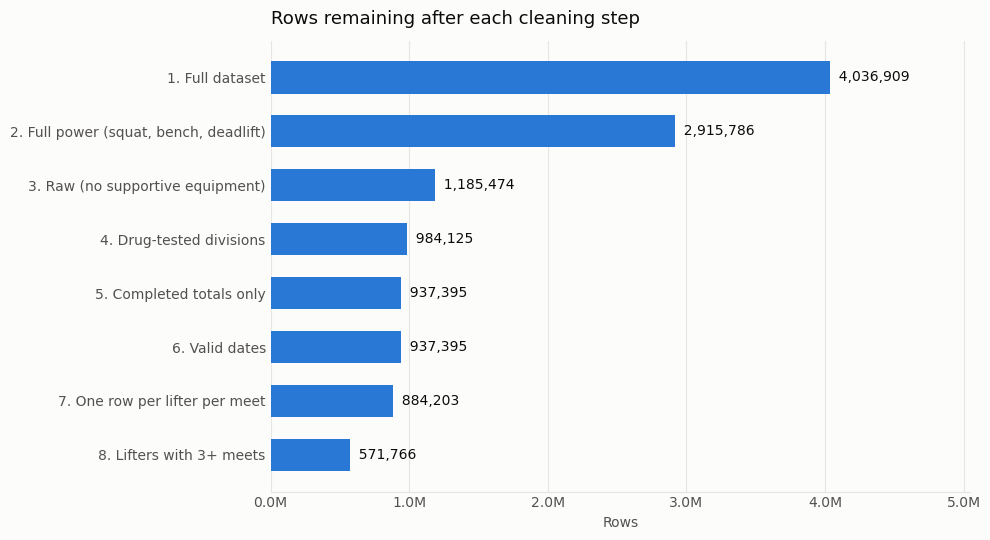

In [9]:
# FIGURE 1: Cleaning funnel - how the sample was built
steps = pd.DataFrame(log)
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(BG)
ax.barh(steps["step"], steps["rows"], color=BLUE, height=0.6)
ax.invert_yaxis()
for k, r in steps.iterrows():
    ax.text(r["rows"], k, f"  {r['rows']:,}", va="center", fontsize=10, color=INK)
ax.set_xlim(0, steps["rows"].max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if steps["rows"].max() >= 1e6 else f"{x:,.0f}"))
ax.set_title("Rows remaining after each cleaning step", loc="left", fontsize=13, color=INK, pad=12)
ax.set_xlabel("Rows", color=MUTED)
style(ax, "x")
plt.tight_layout()
plt.savefig("fig1_cleaning_funnel.png", dpi=200, bbox_inches="tight")
plt.show()
 

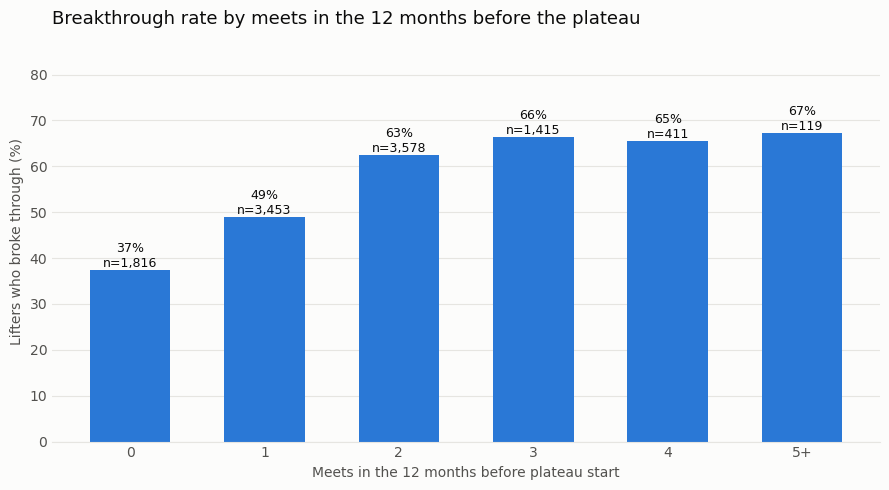

In [10]:
# FIGURE 2: Breakthrough rate by competition frequency
freq = analysis.copy()
freq["Meets"] = freq["CompFrequency"].clip(upper=5).astype(int).astype(str).replace("5", "5+")
order = [m for m in ["0", "1", "2", "3", "4", "5+"] if m in freq["Meets"].unique()]
rate = freq.groupby("Meets")["Breakthrough"].agg(["mean", "size"]).loc[order]
 
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor(BG)
bars = ax.bar(rate.index, rate["mean"] * 100, color=BLUE, width=0.6)
for b, (_, r) in zip(bars, rate.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
            f"{r['mean']:.0%}\nn={int(r['size']):,}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_ylim(0, rate["mean"].max() * 100 * 1.3)
ax.set_title("Breakthrough rate by meets in the 12 months before the plateau",
             loc="left", fontsize=13, color=INK, pad=12)
ax.set_xlabel("Meets in the 12 months before plateau start", color=MUTED)
ax.set_ylabel("Lifters who broke through (%)", color=MUTED)
style(ax)
plt.tight_layout()
plt.savefig("fig2_breakthrough_by_frequency.png", dpi=200, bbox_inches="tight")
plt.show()

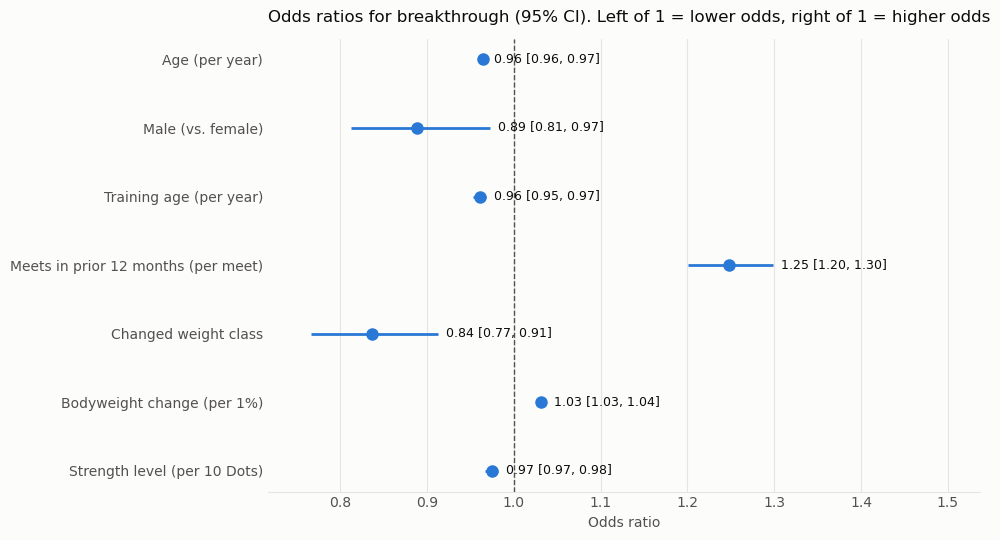

In [11]:
# FIGURE 3: Odds ratios with 95% confidence intervals (forest plot)
labels = {"Age": "Age (per year)", "Male": "Male (vs. female)",
          "TrainingAge": "Training age (per year)", "CompFrequency": "Meets in prior 12 months (per meet)",
          "WeightClassChange": "Changed weight class", "BodyweightChangePct": "Bodyweight change (per 1%)",
          "Dots10": "Strength level (per 10 Dots)"}
plot = odds_table.rename(index=labels).iloc[::-1]
 
fig, ax = plt.subplots(figsize=(10, 5.5))
fig.patch.set_facecolor(BG)
y = np.arange(len(plot))
ax.hlines(y, plot["95% CI low"], plot["95% CI high"], color=BLUE, linewidth=2)
ax.plot(plot["Odds ratio"], y, "o", color=BLUE, markersize=8)
ax.axvline(1, color=MUTED, linewidth=1, linestyle="--")
for k, (_, r) in enumerate(plot.iterrows()):
    ax.text(r["95% CI high"], k, f"  {r['Odds ratio']:.2f} [{r['95% CI low']:.2f}, {r['95% CI high']:.2f}]",
            va="center", fontsize=9, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(plot.index)
lo, hi = plot["95% CI low"].min(), plot["95% CI high"].max()
ax.set_xlim(min(lo, 1) - 0.05, max(hi, 1) + (max(hi, 1) - min(lo, 1)) * 0.45)
ax.set_title("Odds ratios for breakthrough (95% CI). Left of 1 = lower odds, right of 1 = higher odds",
             loc="left", fontsize=12, color=INK, pad=12)
ax.set_xlabel("Odds ratio", color=MUTED)
style(ax, "x")
plt.tight_layout()
plt.savefig("fig3_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()